# 10 - Detection avec Faster R-CNN (torchvision) : 100 % PyTorch, la boucle du cours

Faster R-CNN est un detecteur a deux etages : un reseau de propositions (RPN) suggere des
regions, une tete les classe et affine leurs boites. Plus lent qu'un YOLO, souvent meilleur sur
les petits objets, et entierement dans torchvision (licence BSD). C'est le squelette
d'entrainement du cours avec trois adaptations :

1. le Dataset rend `(image, cible)` ou la cible est un dict `{boxes (n, 4) x1y1x2y2, labels (n,)}`,
   la classe 0 etant reservee au FOND ;
2. `collate_fn = tuple(zip(*batch))` : les images n'ont pas le meme nombre de boites ;
3. la perte est calculee DANS le modele : `model(images, cibles)` rend un dict de pertes.

Aussi : augmentations torchvision v2 qui deplacent les boites avec l'image, nettoyage des boites
degenerees, export ONNX avec redimensionnement et NMS dans le graphe.

Prerequis : `python tools/get_data/get_neu_det.py` ; poids ImageNet de resnet18 (cache
torchvision, `tools/fetch_weights.py`). Duree en mode QUICK sur 2 coeurs : 3 a 4 minutes.

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 2 Importer -> 3 Cataloguer -> 4 Decouper -> 5 Pretraiter
  -> 6 Augmenter -> 7 Charger par lots -> 8 Modele -> 9 Perte et optimiseur -> 10 Entrainer
  -> 11 Evaluer -> 12 Sauvegarder et exporter -> 13 Predire (dans "Passer en production")
```

## Etape 1 - Imports et reglages

Deux cellules : d'abord REGLAGES (tout ce qu'on change pour ses propres donnees est la, et
seulement la), puis les imports et la preparation (affichage, graine du hasard).

In [1]:
# REGLAGES : tout ce qu'on change pour ses propres donnees est ici.
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres, sur CPU ou GPU) et reseaux de neurones

QUICK = True  # True : essai court sur CPU (240 images, 1 epoque = 1 passage sur les images) ; False : complet (GPU conseille)

IMAGES_DIR = Path("data/raw/neu_det/IMAGES")  # dossier des images NEU-DET (photos de defauts de surface sur de l'acier, 6 classes)
# un XML Pascal VOC par image, de meme nom : il decrit les boites (rectangles) des defauts
ANNOTATIONS_DIR = Path("data/raw/neu_det/ANNOTATIONS")
COLOR = "gray"  # lecture en niveaux de gris (acier sans couleur) ; "rgb" pour des images en couleur
PREPROCESS = []  # pretraitements avant le reseau ([] = aucun) ; ex. [{"name": "clahe", "clip_limit": 2.0, "tile_grid": 8}]
MAX_IMAGES = 240 if QUICK else None  # mode QUICK : 240 images seulement pour aller vite ; None = toutes les images
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # part des images pour la validation (reglages) et pour le test final (note de fin) : 15 % chacune
SEED = 42  # graine du hasard (= runtime.seed de la toolbox) : meme decoupage et meme entrainement que la recette

# augmentations (variations aleatoires des images) : retournements sans risque, ces defauts n'ont pas de sens
AUGMENT = ["hflip"] if QUICK else ["hflip", "vflip"]
TRAINABLE_LAYERS = 3  # blocs du resnet degeles = qui apprennent (0 = backbone, l'extracteur pre-entraine, gele ; 5 = tout)
MIN_SIZE, MAX_SIZE = (224, 320) if QUICK else (320, 512)  # le modele redimensionne lui-meme : petit cote vise, grand cote maximum (pixels)
EPOCHS = 1 if QUICK else 20  # nombre d'epoques : passages complets sur les images d'entrainement
BATCH_SIZE = 4  # lot (batch) : images traitees ensemble a chaque pas ; plus grand = plus rapide mais plus de memoire
# taux d'apprentissage (taille des corrections) ; decroissance des poids (penalite qui garde les poids petits)
LR, WEIGHT_DECAY = 0.01, 1e-4
PATIENCE = 5  # arret anticipe : on stoppe apres ce nombre d'epoques sans progres en validation

CONF_EVAL = 0.001  # score mini pour calculer la mAP (note globale de detection) : il lui faut presque toutes les boites
# score mini en usage ; IoU (recouvrement) au-dela duquel la NMS supprime une boite en double
CONF_PREDICT, IOU_NMS = (0.25, 0.5) if QUICK else (0.5, 0.5)  # 0.5 = valeur de torchvision, comme la recette
VERIFY_CONF = 0.05  # seuil de score fige dans le graphe ONNX (et utilise pour comparer ONNX et PyTorch)
OPSET = 18  # version des operations ONNX (format standard de modele, executable sans PyTorch)

# calcul sur la carte graphique (GPU) si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/10_detection_faster_rcnn")  # dossier ou ce notebook ecrit ses resultats (poids, ONNX, carte du modele)
# decoupage ecrit par la recette (script de production) : sert a verifier qu'on utilise les memes images
RECIPE_SPLIT = Path("outputs/detection/quick_split.csv" if QUICK else "outputs/detection/neu_det_split.csv")
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
print("appareil :", DEVICE, "| mode", "QUICK" if QUICK else "complet")  # affiche ou tourne le calcul et le mode choisi

appareil : cpu | mode QUICK


In [2]:
import contextlib  # contextlib : outils pour les blocs "with" (ici, faire taire les affichages de pycocotools)
import io  # io : flux en memoire ; StringIO = un "faux fichier" texte qui avale ce qu'on veut cacher
import json  # json : lire et ecrire du texte JSON (metriques, carte du modele)
import platform  # platform : infos sur la machine (version de Python notee dans la carte)
import random  # random : tirages au hasard de Python (sa graine est fixee plus bas)
import time  # time : chronometre pour mesurer les durees
import warnings  # warnings : masquer des avertissements connus et sans danger
import xml.etree.ElementTree as ET  # ElementTree : lire les fichiers XML d'annotations
from collections import Counter  # Counter : compte les occurrences (classe la plus frequente d'une image)
from datetime import UTC, datetime  # datetime : date et heure ; UTC = heure universelle, la meme partout

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import matplotlib.pyplot as plt  # matplotlib : tracer des courbes et afficher des images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame), ici le catalogue des images
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.model_selection import train_test_split  # train_test_split : coupe une liste en deux parties tirees au hasard
from torch import nn  # nn : briques des reseaux de neurones (couches, modules)
from torch.utils.data import DataLoader, Dataset  # Dataset : sait lire UN exemple ; DataLoader : les regroupe en lots
from torchvision import tv_tensors  # tv_tensors : tenseurs "etiquetes" (ex. boites) que les augmentations savent deplacer
from torchvision.transforms import v2  # v2 : transformations d'images de torchvision (version 2, qui gere aussi les boites)

from vtb import viz  # viz : affichage de la toolbox (grilles d'images, courbes en direct, tableaux)

viz.setup_notebook(dpi=80, fmt="jpeg")  # reglage des figures : resolution moderee et format jpeg (notebook plus leger)
random.seed(SEED)  # fixe le hasard de Python : memes tirages a chaque execution
np.random.seed(SEED)  # fixe le hasard de numpy
_ = torch.manual_seed(SEED)  # fixe le hasard de PyTorch (poids de depart, melange des lots) ; "_ =" ignore la valeur renvoyee

## Etapes 2 a 4 - Importer, cataloguer, decouper : annotations et decoupage (comme le notebook 08)

Memes fonctions et meme decoupage que les notebooks 08, 09 et 11 : les moteurs se comparent sur
les memes images. Explications detaillees : notebook 08, etapes 2 a 4.

In [3]:
# extensions de fichier acceptees comme images (comparees en minuscules)
IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}


def read_image(path, color="gray"):  # lit une image et la renvoie en gris (H, W) ou en couleur RGB (H, W, 3)
    # octets bruts du fichier puis decodage tel quel (marche aussi avec des accents dans le chemin)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # image a 4 canaux : couleur + transparence (alpha)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur, on jette la transparence
    if color == "gray":  # si on veut du gris
        # image couleur -> gris ; image deja grise : rendue telle quelle
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    # couleur : BGR (ordre d'OpenCV) -> RGB ; gris : canal recopie 3 fois
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def to_three_channels(image):  # renvoie toujours une image a 3 canaux (le reseau attend 3 canaux)
    # deja 3 canaux : inchangee ; gris (2D) : on recopie le canal 3 fois
    return image if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def read_voc(xml_path):  # lit un XML Pascal VOC ; renvoie largeur, hauteur, boites (n, 4) et noms de classes
    root = ET.parse(xml_path).getroot()  # ouvre le XML et prend sa balise racine <annotation>
    # taille de l'image notee dans le XML (float puis int : accepte "200.0")
    width, height = int(float(root.findtext("size/width"))), int(float(root.findtext("size/height")))
    boxes, labels = [], []  # listes a remplir : une boite et un nom de classe par objet
    for obj in root.iter("object"):  # pour chaque objet annote dans l'image
        b = obj.find("bndbox")  # la balise qui contient la boite englobante (bounding box)
        # coins haut-gauche (x1, y1) et bas-droit (x2, y2), en pixels
        x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
        # boite ramenee a l'interieur de l'image si elle deborde
        boxes.append([max(0.0, x1), max(0.0, y1), min(float(width), x2), min(float(height), y2)])
        labels.append(obj.findtext("name").strip())  # nom de la classe, sans espaces autour
    # reshape(-1, 4) : tableau (0, 4) meme sans objet, pour garder la meme forme
    return width, height, np.array(boxes, np.float32).reshape(-1, 4), labels


def main_label(labels):  # classe la plus frequente de l'image (sert a equilibrer le decoupage)
    return Counter(labels).most_common(1)[0][0] if labels else "background"  # aucune boite : "background" (fond, image sans defaut)


def holdout(index, labels, fraction, seed):  # tire au hasard une part `fraction` des images ; renvoie leurs index
    counts = labels.value_counts()  # nombre d'images par classe principale
    # stratifier (memes proportions de classes dans chaque part) si : 2 classes ou plus, 2 images mini par classe, assez de place
    ok = len(counts) > 1 and counts.min() >= 2 and fraction * len(labels) >= len(counts)
    # stratifie si possible ; "_" = la part gardee (inutile ici), "held" = la part mise de cote
    _, held = train_test_split(index, test_size=fraction, stratify=labels if ok else None, random_state=seed)
    return pd.Index(held)  # index pandas des images mises de cote


records = []  # une fiche par image : chemin, taille, boites, classes
# chaque fichier image du dossier (sous-dossiers compris), trie par nom
for image_path in sorted(p for p in IMAGES_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS):
    # son XML porte le meme nom (stem = nom sans extension)
    width, height, boxes, labels = read_voc(ANNOTATIONS_DIR / f"{image_path.stem}.xml")
    # range la fiche de l'image
    records.append({"path": str(image_path), "width": width, "height": height, "boxes": boxes, "labels": labels})
# liste triee des classes presentes : leur position donne leur numero
CLASS_NAMES = sorted({label for r in records for label in r["labels"]})
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}  # nom de classe -> numero (0, 1, 2...), ce que le reseau manipule
by_path = {r["path"]: r for r in records}  # chemin -> fiche, pour retrouver une fiche vite

# tableau : une ligne par image avec sa classe principale
catalog = pd.DataFrame([{"path": r["path"], "label": main_label(r["labels"])} for r in records])
if MAX_IMAGES is not None and len(catalog) > MAX_IMAGES:  # si on limite le nombre d'images (mode QUICK)
    # tire MAX_IMAGES images au hasard (random_state=0 : toujours les memes), remises dans l'ordre
    catalog = catalog.sample(n=MAX_IMAGES, random_state=0).sort_values("path").reset_index(drop=True)
labels = catalog["label"].astype(str)  # classe principale de chaque image, en texte
catalog["split"] = "train"  # par defaut, chaque image va dans l'entrainement
catalog.loc[holdout(catalog.index, labels, TEST_FRACTION, SEED), "split"] = "test"  # 15 % des images mises de cote pour le test
rest = catalog[catalog["split"] == "train"]  # les images restantes
# 15 % du total pris dans le reste pour la validation (0.15 / 0.85 du reste)
catalog.loc[holdout(rest.index, labels[rest.index], VAL_FRACTION / (1 - TEST_FRACTION), SEED), "split"] = "val"
catalog.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage pour le relire ou le comparer
SPLIT_MATCHES_RECIPE = None  # None = pas de decoupage de recette a comparer
if RECIPE_SPLIT.exists():  # si la recette a deja ecrit son decoupage
    # on le lit (keep_default_na=False : aucun texte lu comme valeur manquante)
    recipe = pd.read_csv(RECIPE_SPLIT, keep_default_na=False)[["path", "split"]]
    # jointure par chemin : True si chaque image est dans la meme part (train/val/test) que dans la recette
    SPLIT_MATCHES_RECIPE = bool(catalog[["path", "split"]].merge(recipe, on="path", suffixes=("", "_r")).eval("split == split_r").all())
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # True attendu (None si la recette n'a pas encore tourne)
# liste des fiches de chaque part : train, val, test
subsets = {s: [by_path[p] for p in catalog.loc[catalog["split"] == s, "path"]] for s in ("train", "val", "test")}
print({s: len(v) for s, v in subsets.items()}, CLASS_NAMES)  # nombre d'images par part et liste des classes

decoupage identique a la recette : True
{'train': 168, 'val': 36, 'test': 36} ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


## Etapes 5 a 7 - Pretraiter, augmenter, charger par lots : le Dataset (une image, un dict de cibles) et des augmentations qui deplacent les boites

- l'image est un tenseur float `(3, H, W)` dans [0, 1] (pas de normalisation : le modele la
  fait lui-meme avec les statistiques ImageNet) ;
- `labels` est decale de +1 : 0 = fond pour Faster R-CNN ;
- torchvision v2 transforme l'image ET les boites (`tv_tensors.BoundingBoxes`) : un
  retournement retourne aussi les boites. Apres une augmentation qui recadre ou tourne, une
  boite peut sortir de l'image ou devenir plate : on la retire avec son etiquette (une boite
  de largeur nulle fait diverger la perte de regression).

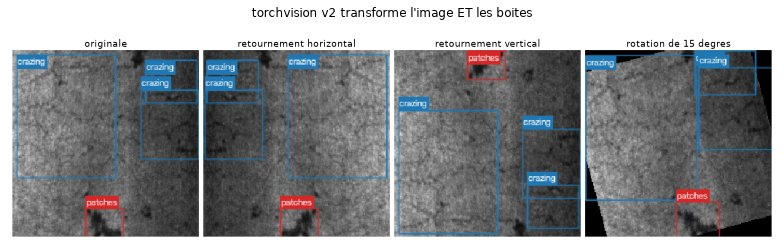

In [4]:
def preprocess(image, steps=PREPROCESS):  # applique les pretraitements choisis (ex. CLAHE) ; renvoie l'image modifiee
    for step in steps:  # pour chaque operation demandee, dans l'ordre
        params = {k: v for k, v in step.items() if k != "name"}  # ses parametres : tout sauf le nom
        if step["name"] == "clahe":  # CLAHE : egalisation de contraste par zones, fait ressortir les details fins
            grid = int(params.get("tile_grid", 8))  # l'image est decoupee en grid x grid tuiles (8 par defaut)
            # contraste limite par clip_limit pour ne pas amplifier le bruit
            image = cv2.createCLAHE(clipLimit=float(params.get("clip_limit", 2.0)), tileGridSize=(grid, grid)).apply(image)
        else:  # operation inconnue de ce notebook
            # on arrete avec un message clair
            raise ValueError(f"operation {step['name']} non ecrite dans ce notebook (catalogue : notebook 02)")
    return image  # image pretraitee, meme taille que l'entree


def to_tensor(image):  # convertit une image numpy en tenseur PyTorch (3, H, W) a valeurs entre 0 et 1
    """uint8 (H, W) ou (H, W, 3) -> float (3, H, W) dans [0, 1]."""
    image = to_three_channels(image)  # 3 canaux dans tous les cas
    scale = 65535.0 if image.dtype == np.uint16 else 255.0  # valeur maximale possible : 65535 pour une image 16 bits, 255 sinon
    # (H, W, C) -> (C, H, W), en nombres a virgule, ramenes entre 0 et 1
    return torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float() / scale


def sanitize(boxes, labels, min_size=1.0):  # retire les boites trop petites ; renvoie (boites, etiquettes) filtrees
    """Retire les boites devenues degenerees (largeur ou hauteur < min_size) et leurs etiquettes."""
    # vrai pour les boites dont largeur ET hauteur font au moins min_size pixels
    keep = ((boxes[:, 2] - boxes[:, 0]) >= min_size) & ((boxes[:, 3] - boxes[:, 1]) >= min_size)
    return boxes[keep], labels[keep]  # on garde ces boites et leurs etiquettes (meme masque pour les deux)


# les augmentations disponibles : retournement horizontal / vertical, une fois sur deux
FLIPS = {"hflip": v2.RandomHorizontalFlip(0.5), "vflip": v2.RandomVerticalFlip(0.5)}
# enchaine les augmentations choisies, puis ramene les boites dans l'image ; None si aucune
augment = v2.Compose([FLIPS[name] for name in AUGMENT] + [v2.ClampBoundingBoxes()]) if AUGMENT else None


class DetectionDataset(Dataset):  # jeu de donnees PyTorch : rend une image (tenseur) et ses cibles {boxes, labels}
    def __init__(self, items, augment=None):  # items : fiches des images ; augment : augmentations (None hors entrainement)
        self.items, self.augment = items, augment  # on garde les fiches et les augmentations

    def __len__(self):  # nombre d'images du jeu (demande par le DataLoader)
        return len(self.items)  # une image par fiche

    def image(self, i):  # lit l'image numero i, la pretraite et la met en 3 canaux
        return to_three_channels(preprocess(read_image(self.items[i]["path"], COLOR)))  # lecture -> pretraitement -> 3 canaux

    def __getitem__(self, i):  # renvoie l'element i : (image (3, H, W), {"boxes": (n, 4), "labels": (n,)})
        record, image = self.items[i], self.image(i)  # la fiche et l'image pretraitee
        # facteurs image pretraitee / image d'origine (1 sauf si le pretraitement redimensionne)
        sx, sy = image.shape[1] / record["width"], image.shape[0] / record["height"]
        # boites remises dans le repere de l'image pretraitee, en tenseur (n, 4)
        boxes = torch.tensor(record["boxes"] * np.array([sx, sy, sx, sy], np.float32)).reshape(-1, 4)
        # numero de classe + 1 : le 0 est reserve au FOND pour Faster R-CNN
        labels = torch.tensor([CLASS_INDEX[x] + 1 for x in record["labels"]], dtype=torch.int64)
        tensor = to_tensor(image)  # image en tenseur (3, H, W) dans [0, 1]
        if self.augment is not None:  # entrainement : on augmente
            # BoundingBoxes : dit a v2 que ce sont des boites XYXY (coins) sur une image de cette taille
            wrapped = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=tuple(tensor.shape[-2:]))
            tensor, wrapped = self.augment(tensor, wrapped)  # la meme transformation aleatoire s'applique a l'image ET aux boites
            # retour en tenseur simple, et retrait des boites devenues trop petites
            boxes, labels = sanitize(wrapped.as_subclass(torch.Tensor), labels)
        return tensor, {"boxes": boxes, "labels": labels}  # l'image et le dict de cibles attendu par Faster R-CNN


def collate(batch):  # assemble un lot : renvoie (images, cibles) sous forme de tuples
    return tuple(zip(*batch))  # pas d'empilement : chaque image a son nombre de boites (et parfois sa taille)


# entrainement avec augmentations ; validation sans
train_set, val_set = DetectionDataset(subsets["train"], augment), DetectionDataset(subsets["val"])
x, target = DetectionDataset(subsets["train"])[1]  # une image d'entrainement sans augmentation, pour la demonstration
# ses boites, etiquetees pour que les transformations v2 les suivent
boxes = tv_tensors.BoundingBoxes(target["boxes"], format="XYXY", canvas_size=tuple(x.shape[-2:]))
demos = {  # titre -> transformation a montrer (None = image d'origine)
    "originale": None,  # l'image telle quelle
    "retournement horizontal": v2.RandomHorizontalFlip(1.0),  # retournement horizontal force (probabilite 1)
    "retournement vertical": v2.RandomVerticalFlip(1.0),  # retournement vertical force
    "rotation de 15 degres": v2.RandomRotation((15, 15)),  # rotation d'exactement 15 degres
}
shown = []  # images dessinees
for transform in demos.values():  # pour chaque transformation de la demo
    xi, bi = (x, boxes) if transform is None else transform(x, boxes)  # image et boites transformees ensemble (ou inchangees)
    # boites ramenees dans l'image, puis retrait des boites degenerees
    bi, li = sanitize(v2.ClampBoundingBoxes()(bi).as_subclass(torch.Tensor), target["labels"])
    shown.append(  # ajoute l'image dessinee
        # remise en (H, W, C) uint8 0-255 pour dessiner ; etiquettes - 1 pour revenir aux numeros de class_names
        viz.draw_boxes((xi.permute(1, 2, 0).numpy() * 255).astype(np.uint8), bi.numpy(), labels=(li - 1).tolist(), class_names=CLASS_NAMES)
    )
# grille de 4 vignettes avec leurs titres
viz.grid(shown, list(demos), ncols=4, size=2.4, suptitle="torchvision v2 transforme l'image ET les boites")
plt.show()  # affiche

## Etape 8 - Modele : backbone resnet18 ImageNet + FPN, RPN et tete neufs

`resnet_fpn_backbone` prend un resnet18 pre-entraine (ImageNet) et lui ajoute un FPN (Feature
Pyramid Network : une carte par echelle, pour les petits et les grands objets). Seuls les
`TRAINABLE_LAYERS` derniers blocs sont degeles. Le RPN et la tete partent de zero : il faut
plus d'epoques qu'avec un detecteur deja entraine sur COCO (`fasterrcnn_resnet50_fpn_v2`,
configuration `fasterrcnn_resnet50_coco_neudet.yaml` de la recette).

`num_classes = C + 1` (le fond). `min_size, max_size` : le modele redimensionne lui-meme chaque
image (petit cote = `min_size`, grand cote <= `max_size`) et rend ses boites dans le repere de
l'image RECUE : aucun letterbox a defaire.

In [5]:
from torchvision.models import ResNet18_Weights  # poids ImageNet (grand jeu de photos, 1000 classes) du resnet18
from torchvision.models.detection import FasterRCNN  # FasterRCNN : le detecteur a deux etages (propositions puis classement)
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone  # resnet + FPN, pret a servir de backbone


def build_model(pretrained=True):  # construit le detecteur ; renvoie le modele (poids ImageNet pour le backbone si pretrained)
    backbone = resnet_fpn_backbone(  # backbone (extracteur de caracteristiques) : resnet18 + FPN (une carte par echelle)
        backbone_name="resnet18",  # le plus petit resnet : rapide sur CPU
        weights=ResNet18_Weights.DEFAULT if pretrained else None,  # poids ImageNet, ou aucun (on les rechargera depuis best.pt)
        trainable_layers=TRAINABLE_LAYERS,  # seuls les derniers blocs apprennent, les premiers restent geles
    )
    # detecteur complet ; num_classes = classes + 1 (le fond) ; tailles de redimensionnement interne
    # box_nms_thresh : seuil de la NMS finale, passe explicitement pour que la carte du modele dise vrai
    return FasterRCNN(backbone, num_classes=len(CLASS_NAMES) + 1, min_size=MIN_SIZE, max_size=MAX_SIZE, box_nms_thresh=IOU_NMS)


random.seed(SEED)  # meme etat du hasard que la recette au moment de construire le modele (RPN et tete neufs)
np.random.seed(SEED)  # idem pour numpy
_ = torch.manual_seed(SEED)  # idem pour PyTorch (poids de depart du RPN et de la tete)
model = build_model().to(DEVICE)  # modele cree puis envoye sur le GPU ou le CPU
# nombre de poids qui apprennent (requires_grad = recoit un gradient, la correction calculee)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
# taille totale et part entrainable, en millions de parametres
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parametres dont {trainable / 1e6:.1f} M entrainables")

28.3 M parametres dont 28.1 M entrainables


## Etapes 9 et 10 - Perte et optimiseur, entrainer : la boucle d'entrainement (les cinq lignes du cours)

`zero_grad -> pertes = model(images, cibles) -> somme -> backward -> step`. Les pertes : RPN
(objet / fond, regression des propositions) et tete (classe, regression de la boite). Taux :
montee lineaire sur les 200 premieres iterations (la tete neuve donne de grands gradients),
puis cosinus par epoque. Validation : mAP COCO a chaque epoque, meilleur modele garde.

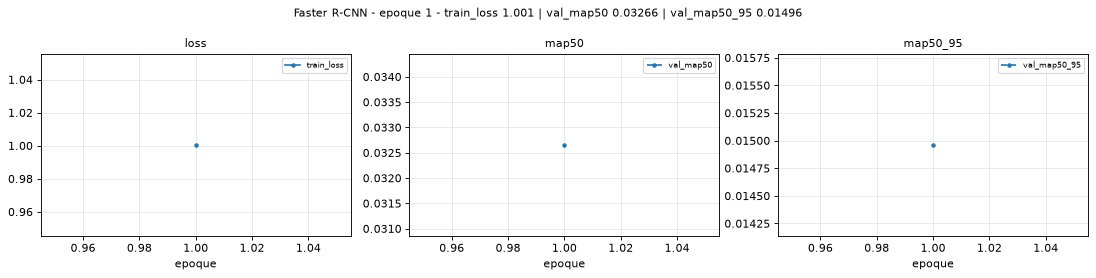

entrainement : 177.2 s ; meilleur mAP50-95 de validation 0.015


In [6]:
from pycocotools.coco import COCO  # pycocotools : calcul officiel de la mAP COCO ; COCO = la verite terrain
from pycocotools.cocoeval import COCOeval  # COCOeval : compare predictions et verite, calcule les precisions moyennes (AP)


def coco_metrics(items, preds, class_names):  # renvoie mAP50, mAP50-95 et AP par classe (verite et predictions en pixels d'origine)
    index = {n: i for i, n in enumerate(class_names)}  # nom de classe -> numero
    images, annotations = [], []  # verite au format COCO : liste des images et liste des boites
    for image_id, record in enumerate(items):  # pour chaque image, avec son numero
        images.append({"id": image_id, "width": record["width"], "height": record["height"]})  # decrit l'image
        for (x1, y1, x2, y2), label in zip(record["boxes"], record["labels"]):  # pour chaque boite vraie de l'image
            w, h = float(x2 - x1), float(y2 - y1)  # largeur et hauteur de la boite
            annotations.append(  # ajoute la boite au format COCO
                {  # une boite = un dictionnaire de champs
                    "id": len(annotations) + 1,  # numero unique de la boite (COCO commence a 1)
                    "image_id": image_id,  # image a laquelle elle appartient
                    "category_id": index[label],  # numero de sa classe
                    "bbox": [float(x1), float(y1), w, h],  # format COCO : coin haut-gauche, largeur, hauteur
                    "area": w * h,  # aire (COCO s'en sert pour les tailles petit / moyen / grand)
                    "iscrowd": 0,  # 0 = objet isole (pas une foule groupee)
                }
            )
    results = [  # predictions au format COCO : une entree par boite predite
        {  # une prediction
            "image_id": i,  # image concernee
            "category_id": int(r[5]),  # classe predite
            "bbox": [float(r[0]), float(r[1]), float(r[2] - r[0]), float(r[3] - r[1])],  # x, y, largeur, hauteur
            "score": float(r[4]),  # score de confiance
        }
        for i, rows in enumerate(preds)  # pour chaque image et ses detections
        for r in rows  # pour chaque detection [x1 y1 x2 y2 score classe]
    ]
    if not results:  # aucune detection (modele encore nul)
        # tout a zero (pycocotools planterait sur une liste vide)
        return {"map50": 0.0, "map50_95": 0.0, "per_class": {n: {"ap50": 0.0, "ap50_95": 0.0} for n in class_names}}
    with contextlib.redirect_stdout(io.StringIO()):  # tout ce que pycocotools affiche part dans un faux fichier : sortie propre
        truth = COCO()  # objet verite terrain vide
        truth.dataset = {  # on le remplit a la main (au lieu de lire un fichier JSON)
            "images": images,  # les images
            "annotations": annotations,  # les boites vraies
            "categories": [{"id": i, "name": n} for i, n in enumerate(class_names)],  # les classes
        }
        truth.createIndex()  # construit les tables de recherche internes
        evaluator = COCOeval(truth, truth.loadRes(results), iouType="bbox")  # evaluation de boites (pas de masques)
        evaluator.evaluate()  # apparie predictions et verites, image par image et classe par classe
        evaluator.accumulate()  # construit les courbes precision-rappel
        evaluator.summarize()  # calcule les 12 chiffres resumes (evaluator.stats)
    # precision par (seuil IoU, rappel, classe) ; toutes tailles d'objets, 100 detections max
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    per_class = {}  # AP de chaque classe
    for k, class_id in enumerate(evaluator.params.catIds):  # pour chaque classe evaluee
        # -1 = pas de donnee : on l'ecarte ; at50 = seuil IoU 0.5 seul, valid = tous les seuils
        at50, valid = precision[0, :, k][precision[0, :, k] > -1], precision[:, :, k][precision[:, :, k] > -1]
        per_class[class_names[class_id]] = {  # AP de la classe
            "ap50": round(float(at50.mean()), 4) if at50.size else 0.0,  # AP a IoU 0.5 (boite juste si recouvrement >= 50 %)
            "ap50_95": round(float(valid.mean()), 4) if valid.size else 0.0,  # moyenne sur les seuils IoU 0.5 a 0.95 (plus exigeant)
        }
    # stats[0] = mAP50-95, stats[1] = mAP50
    return {"map50": float(evaluator.stats[1]), "map50_95": float(evaluator.stats[0]), "per_class": per_class}


@torch.no_grad()  # pas de calcul de gradient ici : plus rapide, moins de memoire
def predict_images(net, images, conf, batch_size=4):  # predit des images deja pretraitees ; renvoie un tableau (n, 6) par image
    """Images pretraitees -> (n, 6) [x1 y1 x2 y2 score classe] dans le repere de ces images."""
    net.eval()  # mode evaluation : BatchNorm figee, le modele rend des detections au lieu des pertes
    net.roi_heads.score_thresh = conf  # seuil de score applique DANS le modele, avant la NMS (suppression des doublons) de la tete
    out = []  # resultats par image
    for begin in range(0, len(images), batch_size):  # par paquets de batch_size images
        # images du paquet en tenseurs, sur l'appareil (une liste : les tailles peuvent differer)
        tensors = [to_tensor(im).to(DEVICE) for im in images[begin : begin + batch_size]]
        for result in net(tensors):  # pour chaque image : un dict boxes / scores / labels
            # ramenes en numpy ; labels - 1 : on retire la case du fond pour revenir aux numeros de class_names
            rows = [result["boxes"].cpu().numpy(), result["scores"].cpu().numpy(), result["labels"].cpu().numpy() - 1]
            # colonnes x1 y1 x2 y2 score classe ; reshape garde la forme (0, 6) sans detection
            out.append(np.column_stack(rows).astype(np.float32).reshape(-1, 6))
    return out  # une entree par image


def predict_paths(net, paths, conf, batch_size=8):  # predit des fichiers images ; renvoie les boites dans l'image d'origine
    """Fichiers -> (n, 6) dans le repere de l'image d'ORIGINE (le chemin de production)."""
    out = []  # resultats par image
    for begin in range(0, len(paths), batch_size):  # par paquets de batch_size chemins
        originals = [read_image(p, COLOR) for p in paths[begin : begin + batch_size]]  # lit les images du paquet
        images = [preprocess(o) for o in originals]  # les pretraite
        for original, image, rows in zip(originals, images, predict_images(net, images, conf)):  # chaque image et ses detections
            rows[:, [0, 2]] *= original.shape[1] / image.shape[1]  # x : image pretraitee -> image d'origine
            rows[:, [1, 3]] *= original.shape[0] / image.shape[0]  # y : idem
            out.append(rows)  # range
    return out  # une entree par chemin, dans l'ordre


loader = DataLoader(  # distribue les images d'entrainement par lots
    train_set,  # jeu d'entrainement (avec augmentations)
    batch_size=BATCH_SIZE,  # images par lot
    shuffle=True,  # ordre melange a chaque epoque
    collate_fn=collate,  # lots assembles en tuples (pas d'empilement)
    num_workers=0,  # lecture dans le processus principal (simple et reproductible)
    generator=torch.Generator().manual_seed(SEED),  # melange reproductible (graine fixee)
)
# optimiseur (corrige les poids) SGD sur les poids entrainables ; momentum 0.9 : garde l'elan des pas precedents
optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=LR, momentum=0.9, weight_decay=WEIGHT_DECAY)
warmup = min(200, len(loader))  # echauffement : au plus 200 iterations (une iteration = un lot), sans depasser une epoque
# taux multiplie par (it + 1) / warmup : montee lineaire jusqu'a 1
warmup_scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda it: min(1.0, (it + 1) / warmup))
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, EPOCHS))  # puis descente en cosinus, un pas par epoque
# courbes mises a jour en direct a chaque epoque
live = viz.LivePlot(metrics=("train_loss", "val_map50", "val_map50_95"), title="Faster R-CNN")
# meilleure mAP vue (-1 : rien encore), epoques sans progres, compteur d'iterations, heure de depart
best, bad, iteration, start = -1.0, 0, 0, time.perf_counter()
for epoch in range(1, EPOCHS + 1):  # pour chaque epoque (numerotees a partir de 1)
    model.train()  # mode entrainement : le modele rend ses pertes
    total = 0.0  # somme des pertes sur l'epoque
    for images, targets in loader:  # pour chaque lot d'images et de cibles
        images = [i.to(DEVICE) for i in images]  # images sur l'appareil de calcul
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]  # chaque tenseur des cibles aussi
        optimizer.zero_grad(set_to_none=True)  # efface les gradients du lot precedent
        # perte (erreur a reduire) calculee dans le modele : dict loss_classifier, loss_box_reg, loss_objectness, loss_rpn_box_reg
        losses = model(images, targets)
        loss = sum(losses.values())  # perte totale = somme des quatre
        loss.backward()  # calcule les gradients (retropropagation)
        optimizer.step()  # corrige les poids dans le sens qui reduit la perte
        if iteration < warmup:  # si on est encore dans l'echauffement
            warmup_scheduler.step()  # le taux monte d'un cran
        iteration += 1  # une iteration de plus
        total += loss.item()  # item() : tenseur -> nombre Python
    cosine.step()  # fin d'epoque : un pas de la descente en cosinus
    # mAP de validation, en predisant depuis les fichiers (chemin de production)
    val = coco_metrics(subsets["val"], predict_paths(model, [r["path"] for r in subsets["val"]], CONF_EVAL), CLASS_NAMES)
    if val["map50_95"] > best + 1e-3:  # vrai progres (plus de 0.001)
        best, bad = val["map50_95"], 0  # nouveau record, compteur remis a zero
        # sauvegarde le meilleur modele
        torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_map50_95": best}, OUT / "best.pt")
    else:  # pas de progres
        bad += 1  # une epoque de plus sans progres
    # ajoute un point aux courbes (perte moyenne par lot, mAP de validation)
    live.update(epoch, train_loss=total / len(loader), val_map50=val["map50"], val_map50_95=val["map50_95"])
    if bad >= PATIENCE:  # trop d'epoques sans progres
        print(f"arret anticipe a l'epoque {epoch}")  # on le signale
        break  # on sort de la boucle des epoques
TRAIN_SECONDS = round(time.perf_counter() - start, 1)  # duree totale d'entrainement en secondes
live.close()  # fige les courbes
live.history.to_csv(OUT / "history.csv", index=False)  # sauvegarde l'historique des metriques
print(f"entrainement : {TRAIN_SECONDS} s ; meilleur mAP50-95 de validation {best:.3f}")  # bilan

## Etape 11 - Evaluer : evaluer et choisir le seuil

Meilleur modele recharge depuis `best.pt` (sans retelecharger les poids ImageNet : ils sont
dans le point de controle). mAP COCO du test, point de fonctionnement, seuil choisi sur la
VALIDATION (meilleur F1). Detail des metriques : notebook 08, etape 11.

test : mAP50 0.068 | mAP50-95 0.032 | 331.9 ms / image
seuil choisi sur la validation : 0.1 -> test {'tp': 8, 'fp': 514, 'fn': 76, 'precision': 0.0153, 'recall': 0.0952, 'f1': 0.0264} | rappel image 1.0
seuil de la recette 0.25 -> test {'tp': 0, 'fp': 0, 'fn': 84, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


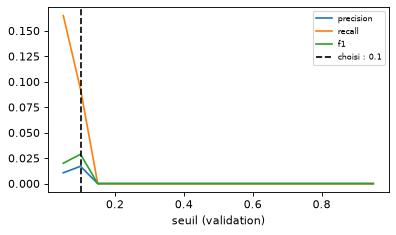

,ap50,ap50_95
crazing,0.0106,0.0019
inclusion,0.0015,0.0003
patches,0.0029,0.0009
pitted_surface,0.3889,0.1899
rolled-in_scale,0.0041,0.0007
scratches,0.0000,0.0000


In [7]:
model = build_model(pretrained=False)  # modele de meme architecture, sans telecharger ImageNet (les poids viennent de best.pt)
# charge les meilleurs poids sauvegardes (weights_only=True : lecture sure)
model.load_state_dict(torch.load(OUT / "best.pt", map_location="cpu", weights_only=True)["model_state"])
model = model.to(DEVICE).eval()  # sur l'appareil de calcul, en mode evaluation


def box_iou(a, b):  # IoU de deux boites [x1, y1, x2, y2] : aire commune / aire de l'union, entre 0 et 1
    # aire de l'intersection (0 si les boites ne se touchent pas)
    inter = max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # aire A + aire B - partie commune
    return float(inter / union) if union > 0 else 0.0  # 0 si les boites sont degenerees (aire nulle)


# compte bonnes et mauvaises detections a un seuil ; renvoie precision, rappel, F1
def operating_point(items, preds, class_names, conf, iou=0.5):
    counts = {n: {"tp": 0, "fp": 0, "fn": 0} for n in class_names}  # par classe : vrais positifs, faux positifs, faux negatifs
    flagged = n_defect = 0  # images a defaut signalees par le modele / images a defaut
    for record, rows in zip(items, preds):  # pour chaque image et ses detections
        kept = rows[rows[:, 4] >= conf]  # detections au-dessus du seuil
        if len(record["labels"]):  # l'image contient au moins un defaut
            n_defect, flagged = n_defect + 1, flagged + bool(len(kept))  # compte l'image, et si le modele y a signale quelque chose
        for k, name in enumerate(class_names):  # classe par classe
            truth = [b for b, label in zip(record["boxes"], record["labels"]) if label == name]  # boites vraies de cette classe
            mine = kept[kept[:, 5] == k]  # boites predites de cette classe
            used = [False] * len(truth)  # chaque boite vraie ne peut etre trouvee qu'une fois
            for row in mine[np.argsort(-mine[:, 4])]:  # predictions de la plus sure a la moins sure
                # IoU avec chaque boite vraie encore libre (-1 si deja prise)
                scores = [box_iou(row[:4], t) if not used[j] else -1.0 for j, t in enumerate(truth)]
                best_j = int(np.argmax(scores)) if scores else -1  # la vraie qui recouvre le mieux (-1 s'il n'y en a pas)
                if best_j >= 0 and scores[best_j] >= iou:  # recouvrement suffisant : bonne detection
                    used[best_j] = True  # cette vraie est prise
                    counts[name]["tp"] += 1  # vrai positif
                else:  # rien de libre ou recouvrement trop faible
                    counts[name]["fp"] += 1  # faux positif (fausse alarme)
            counts[name]["fn"] += used.count(False)  # vraies jamais trouvees = faux negatifs (defauts rates)

    def rates(c):  # precision, rappel et F1 a partir des comptes
        p = c["tp"] / (c["tp"] + c["fp"]) if c["tp"] + c["fp"] else 0.0  # precision : part des detections qui sont justes
        r = c["tp"] / (c["tp"] + c["fn"]) if c["tp"] + c["fn"] else 0.0  # rappel : part des vrais defauts trouves
        # F1 : moyenne harmonique de la precision et du rappel
        return {**c, "precision": round(p, 4), "recall": round(r, 4), "f1": round(2 * p * r / (p + r), 4) if p + r else 0.0}

    total = {k: sum(c[k] for c in counts.values()) for k in ("tp", "fp", "fn")}  # comptes toutes classes confondues
    return {  # resultat
        "conf": conf,  # seuil utilise
        "overall": rates(total),  # toutes classes
        "per_class": {n: rates(c) for n, c in counts.items()},  # classe par classe
        # part des images a defaut ou le modele signale au moins une boite
        "image_recall": round(flagged / n_defect, 4) if n_defect else None,
    }


# detections sur la validation (seuil tres bas : toutes les boites)
val_preds = predict_paths(model, [r["path"] for r in subsets["val"]], CONF_EVAL)
start = time.perf_counter()  # chrono
test_preds = predict_paths(model, [r["path"] for r in subsets["test"]], CONF_EVAL)  # detections sur le test
MS_PER_IMAGE = round(1000 * (time.perf_counter() - start) / len(test_preds), 1)  # temps moyen par image (lecture comprise), en ms
sweep = pd.DataFrame(  # balayage des seuils sur la VALIDATION : une ligne par seuil
    # seuils 0.05, 0.10, ..., 0.95 ; pour chacun precision, rappel, F1 toutes classes
    [{"conf": c, **operating_point(subsets["val"], val_preds, CLASS_NAMES, c)["overall"]} for c in np.round(np.arange(0.05, 0.96, 0.05), 2)]
)
# seuil du meilleur F1 (CONF_PREDICT si F1 nul partout)
CHOSEN_CONF = float(sweep.loc[sweep["f1"].idxmax(), "conf"]) if sweep["f1"].max() > 0 else CONF_PREDICT
test_metrics = coco_metrics(subsets["test"], test_preds, CLASS_NAMES)  # mAP sur le test
op_chosen = operating_point(subsets["test"], test_preds, CLASS_NAMES, CHOSEN_CONF)  # precision / rappel au seuil choisi
op_recipe = operating_point(subsets["test"], test_preds, CLASS_NAMES, CONF_PREDICT)  # et au seuil de la recette
# bilan sur le test
print(f"test : mAP50 {test_metrics['map50']:.3f} | mAP50-95 {test_metrics['map50_95']:.3f} | {MS_PER_IMAGE} ms / image")
# resultats au seuil choisi, et part des images a defaut signalees
print(f"seuil choisi sur la validation : {CHOSEN_CONF} -> test", op_chosen["overall"], "| rappel image", op_chosen["image_recall"])
print(f"seuil de la recette {CONF_PREDICT} -> test", op_recipe["overall"])  # resultats au seuil fixe de la recette
fig, ax = plt.subplots(figsize=(5.5, 3))  # une figure avec un seul graphique
for column in ("precision", "recall", "f1"):  # trois courbes
    ax.plot(sweep["conf"], sweep[column], label=column)  # metrique en fonction du seuil
ax.axvline(CHOSEN_CONF, color="k", linestyle="--", label=f"choisi : {CHOSEN_CONF}")  # trait vertical au seuil choisi
ax.set_xlabel("seuil (validation)")  # titre de l'axe horizontal
ax.legend(fontsize=7)  # legende
plt.show()  # affiche
display(pd.DataFrame(test_metrics["per_class"]).T)  # tableau des AP par classe (une ligne par classe)

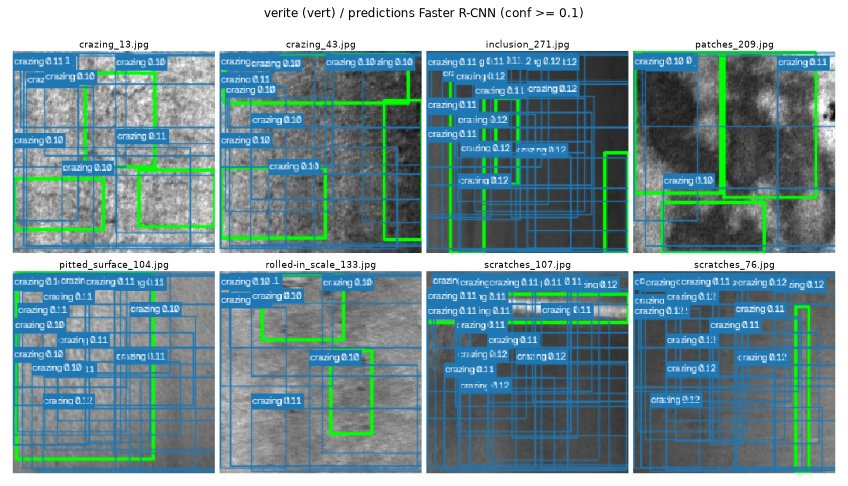

In [8]:
picked = [subsets["test"][i] for i in np.linspace(0, len(subsets["test"]) - 1, 8).astype(int)]  # 8 images de test reparties regulierement
pred_of = {r["path"]: p for r, p in zip(subsets["test"], test_preds)}  # chemin -> detections
viz.grid(  # grille d'images
    [  # une vignette dessinee par image choisie
        viz.draw_detections(  # dessine boites vraies et predites sur l'image
            read_image(r["path"], COLOR),  # image d'origine
            truth={"boxes": r["boxes"], "labels": [CLASS_INDEX[x] for x in r["labels"]]},  # verite terrain (boites et numeros de classe)
            # predictions : boites, classes et scores
            pred={"boxes": pred_of[r["path"]][:, :4], "labels": pred_of[r["path"]][:, 5].astype(int), "scores": pred_of[r["path"]][:, 4]},
            class_names=CLASS_NAMES,  # noms affiches
            conf=CHOSEN_CONF,  # seuil d'affichage
        )
        for r in picked  # pour chaque image choisie
    ],
    [Path(r["path"]).name for r in picked],  # titres : noms des fichiers
    ncols=4,  # 4 colonnes
    size=2.6,  # taille de chaque vignette
    suptitle=f"verite (vert) / predictions Faster R-CNN (conf >= {CHOSEN_CONF})",  # titre general
)
plt.show()  # affiche

## Etape 12 - Sauvegarder et exporter : exporter en ONNX, tout est dans le graphe

Un emballage prend UNE image `(1, 3, H, W)` float [0, 1] et rend trois tableaux : `boxes (n,
4)`, `scores (n,)`, `labels (n,)` (decales de -1 : indice dans `class_names`). Le
redimensionnement interne, le RPN, le ROI pooling et la NMS sont DANS le graphe ; le programme
de production n'a qu'a convertir l'image en float et filtrer les scores. Ancien exporteur
(TorchScript), celui que torchvision teste pour ce modele ; hauteur et largeur dynamiques.

Verification : memes boites ONNX et PyTorch (meme NOMBRE, IoU moyen >= 0,98), y compris sur
une image d'une autre taille (preuve que les dimensions dynamiques fonctionnent).

In [9]:
import onnx  # onnx : lire et ecrire le format ONNX
import onnxruntime as ort  # onnxruntime : moteur qui execute un modele ONNX sans PyTorch


class ExportWrapper(nn.Module):  # emballage pour l'export : un tenseur (1, 3, H, W) en entree, trois tableaux en sortie
    def __init__(self, net):  # on lui donne le Faster R-CNN a emballer
        super().__init__()  # initialisation obligatoire d'un nn.Module
        self.net = net  # le detecteur emballe

    def forward(self, x):  # calcul : x = lot d'une seule image
        result = self.net([x[0]])[0]  # le detecteur attend une LISTE d'images : on lui passe la premiere, on prend son resultat
        # boites, scores, et classes - 1 (indices de class_names, sans le fond)
        return result["boxes"], result["scores"], result["labels"] - 1


def mean_best_iou(mine, reference):  # compare deux jeux de detections ; renvoie nombres de boites et IoU moyen
    ious = [  # pour chaque boite de "mine" : meilleur IoU avec une boite de la reference de la meme image
        max(1.0 if np.allclose(row[:4], r[:4], atol=0.5) else box_iou(row[:4], r[:4]) for r in ref)  # 1 si les coins sont a 0.5 px pres
        for rows, ref in zip(mine, reference)  # image par image
        for row in rows  # boite par boite
        if len(ref)  # seulement si la reference a des boites sur cette image
    ]
    return {  # bilan
        "boxes": int(sum(map(len, mine))),  # nombre de boites de notre chaine
        "reference_boxes": int(sum(map(len, reference))),  # nombre de boites de la reference
        "mean_iou": float(np.mean(ious)) if ious else None,  # IoU moyen (None si rien a comparer)
    }


DEVICE = torch.device("cpu")  # export et verification sur CPU
model = model.cpu().eval()  # modele sur CPU, en mode evaluation
model.roi_heads.score_thresh = VERIFY_CONF  # seuil de score fige dans le graphe : la production filtre ensuite au seuil de la carte
wrapper = ExportWrapper(model).eval()  # l'emballage, en mode evaluation
samples = [preprocess(read_image(r["path"], COLOR)) for r in subsets["val"][:4]]  # 4 images de validation pretraitees
samples.append(cv2.resize(samples[0], (260, 180)))  # une autre taille (260 x 180) : verifie que hauteur et largeur sont bien dynamiques
tensors = [to_tensor(s)[None] for s in samples]  # en tenseurs (1, 3, H, W) ; [None] ajoute l'axe du lot
onnx_path = OUT / "model.onnx"  # fichier ONNX a ecrire
with warnings.catch_warnings():  # les reglages d'avertissements reviennent a la normale a la fin du bloc
    warnings.simplefilter("ignore")  # avertissements de tracage attendus (boucles sur les images)
    torch.onnx.export(  # trace le modele sur un exemple et ecrit le graphe ONNX
        wrapper,  # le modele emballe a exporter
        (tensors[0],),  # exemple d'entree qui sert a suivre les calculs
        str(onnx_path),  # fichier de sortie
        input_names=["input"],  # nom de l'entree dans le graphe
        output_names=["boxes", "scores", "labels"],  # noms des trois sorties
        # hauteur et largeur libres en entree ; nombre de detections n libre en sortie
        dynamic_axes={"input": {2: "height", 3: "width"}, "boxes": {0: "n"}, "scores": {0: "n"}, "labels": {0: "n"}},
        opset_version=max(OPSET, 11),  # version des operations ONNX (11 au minimum pour ce modele)
        dynamo=False,  # exporteur classique par trace (TorchScript), pas le nouveau (dynamo)
    )
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge l'ONNX dans onnxruntime, sur CPU
mine, reference = [], []  # detections ONNX et detections PyTorch de reference
with torch.no_grad():  # sans gradients
    for x in tensors:  # pour chaque image de test de l'export
        boxes, scores, labels = session.run(None, {"input": x.numpy()})  # sorties ONNX
        # en tableau (n, 6) : x1 y1 x2 y2 score classe
        mine.append(np.column_stack([boxes, scores, labels]).astype(np.float32).reshape(-1, 6))
        b, s, k = wrapper(x)  # sorties PyTorch du meme emballage
        reference.append(np.column_stack([b.numpy(), s.numpy(), k.numpy()]).astype(np.float32).reshape(-1, 6))  # meme format, pour comparer
EXPORT_CHECK = mean_best_iou(mine, reference)  # nombres de boites et IoU moyen ONNX contre PyTorch
print(EXPORT_CHECK)  # affiche le bilan
# assert : arrete tout si c'est faux ; ici ONNX et PyTorch doivent rendre autant de boites
assert EXPORT_CHECK["boxes"] == EXPORT_CHECK["reference_boxes"], "nombre de boites different entre ONNX et PyTorch"
assert EXPORT_CHECK["mean_iou"] is None or EXPORT_CHECK["mean_iou"] >= 0.98  # IoU moyen >= 0.98 exige (None : aucune boite a comparer)


def timed(fn, runs=10):  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(2):  # 2 appels d'echauffement (non chronometres)
        fn()  # appel a vide
    begin = time.perf_counter()  # debut du chrono
    for _ in range(runs):  # appels chronometres
        fn()  # appel mesure
    return round(1000 * (time.perf_counter() - begin) / runs, 2)  # duree moyenne en ms


with torch.no_grad():  # sans gradients
    LATENCY = {  # latence (temps d'une prediction) sur une image ; lambda = petite fonction sans nom
        "torch_cpu_ms": timed(lambda: wrapper(tensors[0])),  # PyTorch
        "onnxruntime_cpu_ms": timed(lambda: session.run(None, {"input": tensors[0].numpy()})),  # onnxruntime
    }
print(LATENCY)  # temps par image : PyTorch contre onnxruntime

{'boxes': 173, 'reference_boxes': 173, 'mean_iou': 1.0}


{'torch_cpu_ms': 342.44, 'onnxruntime_cpu_ms': 402.49}


## Etape 12 - Sauvegarder et exporter : la carte du modele

`resize: none` (le modele redimensionne lui-meme), `dynamic_batch: false` (une image a la fois),
`scale: divide by 255`, pas de mean / std (dans le graphe). Le prefixe `fasterrcnn:` choisit le
decodeur : garder les lignes dont le score depasse `thresholds.conf`.

In [10]:
card = {  # carte du modele : tout ce qu'il faut pour l'utiliser sans ce notebook
    "task": "detection",  # type de tache
    "model_name": "fasterrcnn:fasterrcnn_resnet18_fpn",  # le prefixe "fasterrcnn:" choisit le decodeur en production
    "created_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),  # date de creation (heure universelle)
    "framework": {  # versions des outils, pour reproduire
        "python": platform.python_version(),  # version de Python
        "torch": torch.__version__,  # version de PyTorch
        "onnx": onnx.__version__,  # version d'onnx
        "onnxruntime": ort.__version__,  # version d'onnxruntime
    },
    "input": {  # comment preparer l'entree
        "name": "input",  # nom de l'entree du graphe
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": samples[0].shape[0],  # hauteur d'exemple (libre en realite)
        "width": samples[0].shape[1],  # largeur d'exemple (libre en realite)
        "channels": 3,  # 3 canaux
        "color": "RGB",  # ordre RGB
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255",  # valeurs divisees par 255 (0-1)
        "mean": [],  # pas de soustraction de moyenne (faite dans le graphe)
        "std": [],  # pas de division par un ecart-type (faite dans le graphe)
        "resize": "none",  # pas de redimensionnement : le modele le fait lui-meme
        "letterbox_pad_value": None,  # pas de fond de remplissage (pas de letterbox)
        "dynamic_batch": False,  # une image a la fois
        "read_color": COLOR,  # mode de lecture du fichier (gris ou couleur)
    },
    "preprocess": PREPROCESS,  # pretraitements a appliquer avant (ex. CLAHE)
    "outputs": [  # description des trois sorties
        {"name": "boxes", "shape": ["n", 4], "description": "x1, y1, x2, y2 dans l'image recue"},  # boites, dans le repere de l'image recue
        {"name": "scores", "shape": ["n"], "description": "score de la classe"},  # scores
        {"name": "labels", "shape": ["n"], "description": "indice dans class_names"},  # classes
    ],
    "class_names": CLASS_NAMES,  # noms des classes, dans l'ordre des numeros
    "thresholds": {"conf": CHOSEN_CONF, "iou_nms": IOU_NMS},  # seuils a utiliser
    "postprocess": {  # comment lire la sortie
        # tout est dans le graphe : il reste a garder les scores >= seuil de la carte
        "steps": f"redimensionnement et NMS dans le graphe (scores >= {VERIFY_CONF}) ; garder score >= thresholds.conf ; une image a la fois"
    },
    "metrics": {  # performances sur le test
        "map50": test_metrics["map50"],  # mAP a IoU 0.5
        "map50_95": test_metrics["map50_95"],  # mAP moyenne sur IoU 0.5 a 0.95
        "n_images": len(subsets["test"]),  # nombre d'images de test
        "operating_point": op_chosen["overall"],  # precision / rappel / F1 au seuil choisi
    },
    "latency_ms": LATENCY,  # temps par image
    "files": {"onnx": "model.onnx"},  # fichier du modele, dans le meme dossier
    "notes": f"notebook 10 ; verification ONNX : {EXPORT_CHECK}",  # trace de la verification d'export
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible (indent=2)
print(json.dumps(card["input"], indent=1))  # affiche la partie "entree"

{
 "name": "input",
 "layout": "NCHW",
 "height": 200,
 "width": 200,
 "channels": 3,
 "color": "RGB",
 "dtype": "float32",
 "scale": "divide by 255",
 "mean": [],
 "std": [],
 "resize": "none",
 "letterbox_pad_value": null,
 "dynamic_batch": false,
 "read_color": "gray"
}


## Adapter a tes donnees

- Annotations : `IMAGES_DIR`, `ANNOTATIONS_DIR` ; autre format : remplacer `read_voc` (notebook 04).
- Petits defauts sur grandes images : monter `MIN_SIZE, MAX_SIZE` (le modele reduit l'image a
  `min_size` de petit cote) ou passer par des tuiles (notebook 08, etape 13 "inference par tuiles").
- Detecteur deja entraine sur COCO (plus precis, plus lent) : `fasterrcnn_resnet50_fpn_v2(weights="DEFAULT")`
  puis remplacer `roi_heads.box_predictor` par `FastRCNNPredictor(in_features, C + 1)`.
- Augmentations : toute transformation torchvision v2 suit les boites (rotation, recadrage...) ;
  garder `sanitize` apres celles qui coupent l'image.

## Resultats

In [11]:
recipe_file = Path("outputs/detection/quick_fasterrcnn/test_metrics.json")  # metriques ecrites par la recette quick_fasterrcnn
recipe = json.loads(recipe_file.read_text()) if QUICK and recipe_file.exists() else {}  # lues si disponibles (en mode QUICK seulement)
rows = {  # tableau de comparaison : une entree par source
    "notebook 10": {  # resultats de ce notebook
        "mAP50": test_metrics["map50"],  # mAP a IoU 0.5
        "mAP50-95": test_metrics["map50_95"],  # mAP sur IoU 0.5 a 0.95
        f"precision @ {CONF_PREDICT}": op_recipe["overall"]["precision"],  # precision au seuil de la recette
        f"rappel @ {CONF_PREDICT}": op_recipe["overall"]["recall"],  # rappel au seuil de la recette
        "entrainement (s)": TRAIN_SECONDS,  # duree d'entrainement
        "IoU export": EXPORT_CHECK["mean_iou"],  # IoU moyen de la verification d'export
        "ONNX (ms)": LATENCY["onnxruntime_cpu_ms"],  # temps ONNX par image
    }
}
if recipe:  # si la recette a tourne
    rows["recette quick_fasterrcnn"] = {  # ses resultats, pour comparer
        "mAP50": recipe["map50"],  # mAP50
        "mAP50-95": recipe["map50_95"],  # mAP50-95
        f"precision @ {CONF_PREDICT}": recipe["operating_point"]["overall"]["precision"],  # precision au meme seuil
        f"rappel @ {CONF_PREDICT}": recipe["operating_point"]["overall"]["recall"],  # rappel au meme seuil
    }
viz.metrics_table(rows)  # affiche le tableau

,mAP50,mAP50-95,precision @ 0.25,rappel @ 0.25,entrainement (s),IoU export,ONNX (ms)
notebook 10,0.068,0.032,0.0,0.0,177.2,1.0,402.49
recette quick_fasterrcnn,0.068,0.032,0.0,0.0,NaN,NaN,NaN


## Passer en production

```
python recipes/detection/scripts/run.py --config recipes/detection/configs/quick_fasterrcnn.yaml
python -m vtb.serve --model outputs/notebooks/10_detection_faster_rcnn
```

Controle : `vtb.serve.predictor.OnnxPredictor` (sans PyTorch) relit le dossier exporte et doit
rendre les memes boites que l'ONNX appele directement.

In [12]:
print(  # affiche le fichier de configuration de la recette correspondante
    Path(  # chemin du fichier YAML (selon le mode)
        # configuration QUICK ou complete
        "recipes/detection/configs/quick_fasterrcnn.yaml" if QUICK else "recipes/detection/configs/fasterrcnn_resnet18_neudet.yaml"
    ).read_text()  # lu en texte
)

# Verification rapide de la chaine Faster R-CNN (CPU) : memes 240 images, 1 epoque, backbone resnet18 ImageNet.
data:
  root: data/raw/neu_det/IMAGES
  layout: annotations
  annotations_dir: data/raw/neu_det/ANNOTATIONS
  annotation_format: voc
  color: gray
  max_images: 240
split: {file: outputs/detection/quick_split.csv, strategy: stratified, val_fraction: 0.15, test_fraction: 0.15}
augment:
  - {name: hflip}                        # torchvision v2 retourne les boites avec l'image
backend: fasterrcnn
fasterrcnn:
  backbone: resnet18_fpn
  pretrained: imagenet                   # seul le backbone est pre-entraine ; RPN et tete partent de zero
  trainable_layers: 3
  min_size: 224
  max_size: 320
  epochs: 1
  batch_size: 4
  lr: 0.01
export: {openvino: true, latency_runs: 3}
runtime: {output_dir: outputs/detection/quick_fasterrcnn, num_workers: 0}



In [13]:
CONTROL_CONF = VERIFY_CONF  # seuil bas du controle : celui fige dans le graphe, le plus de boites possible
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - la toolbox n'intervient qu'ici, pour le controle

predictor = OnnxPredictor(OUT)  # charge le dossier exporte (ONNX + carte), comme le fait le service


def notebook_rows(original, conf):  # chaine de ce notebook ; renvoie les boites (n, 6) dans l'image d'origine
    """La chaine de ce notebook, de l'image lue aux boites dans l'image d'origine."""
    image = preprocess(original)  # pretraitement
    boxes, scores, labels = session.run(None, {"input": to_tensor(image)[None].numpy()})  # ONNX directement ; [None] ajoute l'axe du lot
    rows = np.column_stack([boxes, scores, labels]).astype(np.float32).reshape(-1, 6)  # tableau (n, 6) : x1 y1 x2 y2 score classe
    rows = rows[rows[:, 4] >= conf]  # garde les scores au-dessus du seuil
    # x -> image d'origine, bornes a la largeur de l'image
    rows[:, [0, 2]] = (rows[:, [0, 2]] * original.shape[1] / image.shape[1]).clip(0, original.shape[1])
    # y -> image d'origine, bornes a la hauteur
    rows[:, [1, 3]] = (rows[:, [1, 3]] * original.shape[0] / image.shape[0]).clip(0, original.shape[0])
    return rows  # detections


worst, compared = 0.0, 0  # plus grand ecart vu, nombre de boites comparees
for conf in (CHOSEN_CONF, CONTROL_CONF):  # le seuil de la carte, puis un seuil bas pour comparer beaucoup de boites
    predictor.card.thresholds["conf"] = conf  # le predicteur utilise ce seuil
    for r in subsets["test"][:10]:  # 10 images de test
        original = read_image(r["path"], COLOR)  # image d'origine
        rows, served = notebook_rows(original, conf), predictor(original)["objects"]  # boites du notebook et du predicteur de production
        # meme nombre de boites, sinon arret
        assert len(served) == len(rows), f"{Path(r['path']).name} : {len(served)} objets servis contre {len(rows)}"
        if len(rows):  # s'il y a des boites
            # plus grand ecart de coordonnee (memes boites, meme ordre)
            worst = max(worst, float(np.abs(np.array([o["box"] for o in served]) - rows[:, :4]).max()))
            compared += len(rows)  # compte les boites comparees
predictor.card.thresholds["conf"] = CHOSEN_CONF  # remet le seuil choisi
# bilan du controle
print(f"OnnxPredictor (production) == notebook : {compared} boites sur 10 images de test, ecart max {worst:.2f} px (arrondi a 0,1 px)")
assert worst <= 0.15  # ecart tolere : l'arrondi a 0.1 px du predicteur
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # rappel du controle du decoupage

OnnxPredictor (production) == notebook : 494 boites sur 10 images de test, ecart max 0.05 px (arrondi a 0,1 px)
decoupage identique a la recette : True


## Pour aller plus loin

- `QUICK = False` (20 epoques, 320-512 px, retournements H et V) sur GPU : `prompts/03`.
- Ancres adaptees aux defauts tres allonges (rayures) : `AnchorGenerator(sizes, aspect_ratios)`
  passe a `FasterRCNN(..., rpn_anchor_generator=...)`.
- Meme decoupage, autres moteurs : notebooks 08, 09, 11.